# Interpolation Model for Pollution Prediction - Analysis

This notebook performs:
1. **Data Loading** - Load EEA parquet files
2. **Exploratory Data Analysis** - Distribution, temporal patterns, correlations
3. **Model Training** - Using PolPred (IDW + HistGradientBoosting)
4. **Model Evaluation** - MAE, RMSE, R², real vs predicted plots

In [ ]:
# Install dependencies if needed
# !pip install pandas numpy matplotlib seaborn scikit-learn pyarrow

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 1. Data Loading

Load EEA parquet files and combine into a single DataFrame.

In [2]:
# Configuration - UPDATE THIS PATH
DATA_DIR = "./E2a/"  # Folder with parquet files

# Station coordinates (Bucharest EEA stations)
STATION_COORDS = {
    "RO0065A": (44.4145, 26.1183, "B-1"),
    "RO0066A": (44.4384, 26.0513, "B-4"),
    "RO0067A": (44.4105, 26.0678, "B-3"),
    "RO0068A": (44.4264, 26.1246, "B-2"),
    "RO0069A": (44.4476, 26.0803, "B-6"),
    "RO0070A": (44.4498, 26.0229, "B-5"),
    "RO0229A": (44.4180, 26.1608, "B-2-old"),
}

# EEA pollutant codes
POLLUTANT_CODES = {
    5: "pm10",
    8: "no2",
    10: "co",
    6001: "pm2_5",
}

In [3]:
def extract_station_code(samplingpoint: str) -> str:
    """Extract station code from Samplingpoint string."""
    sp = samplingpoint.replace("RO/", "")
    parts = sp.split("_")
    if parts and parts[0].startswith("SPO-"):
        return parts[0].replace("SPO-", "")
    return "UNKNOWN"

def load_parquet_files(data_dir: str) -> pd.DataFrame:
    """Load all parquet files and combine."""
    data_path = Path(data_dir)
    parquet_files = list(data_path.glob("*.parquet"))
    
    print(f"Found {len(parquet_files)} parquet files")
    
    all_data = []
    
    for pf in parquet_files:
        try:
            df = pd.read_parquet(pf)
            station_code = extract_station_code(df['Samplingpoint'].iloc[0])
            
            if station_code not in STATION_COORDS:
                continue
            
            lat, lon, name = STATION_COORDS[station_code]
            pollutant_code = df['Pollutant'].iloc[0]
            pollutant_name = POLLUTANT_CODES.get(pollutant_code)
            
            if pollutant_name not in ['pm10', 'pm2_5', 'no2', 'co']:
                continue
            
            station_df = pd.DataFrame({
                'timestamp': df['Start'],
                'station_id': name,
                'lat': lat,
                'lon': lon,
                'pollutant': pollutant_name,
                'value': pd.to_numeric(df['Value'], errors='coerce')
            })
            
            station_df = station_df.dropna(subset=['value'])
            station_df = station_df[station_df['value'] >= 0]
            
            all_data.append(station_df)
            print(f"  Loaded {pf.name}: {len(station_df)} rows, station={name}, pollutant={pollutant_name}")
            
        except Exception as e:
            print(f"  Error loading {pf.name}: {e}")
    
    combined = pd.concat(all_data, ignore_index=True)
    
    # Pivot to wide format
    pivoted = combined.pivot_table(
        index=['timestamp', 'station_id', 'lat', 'lon'],
        columns='pollutant',
        values='value',
        aggfunc='mean'
    ).reset_index()
    
    pivoted.columns.name = None
    
    for pol in ['pm10', 'pm2_5', 'no2', 'co']:
        if pol not in pivoted.columns:
            pivoted[pol] = np.nan
    
    return pivoted

In [4]:
# Load data
df = load_parquet_files(DATA_DIR)

print(f"\n{'='*60}")
print("DATA SUMMARY")
print('='*60)
print(f"Total rows: {len(df)}")
print(f"Date range: {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Stations: {sorted(df['station_id'].unique())}")
print(f"\nPollutant coverage:")
for pol in ['pm10', 'pm2_5', 'no2', 'co']:
    if pol in df.columns:
        valid = df[pol].notna().sum()
        pct = 100 * valid / len(df)
        print(f"  {pol}: {valid} values ({pct:.1f}%)")

Found 21 parquet files
  Loaded SPO-RO0069A_00008_100.parquet: 2151 rows, station=B-6, pollutant=no2
  Loaded SPO-RO0070A_00005_101.parquet: 2145 rows, station=B-5, pollutant=pm10
  Loaded SPO-RO0065A_00010_100.parquet: 2116 rows, station=B-1, pollutant=co
  Loaded SPO-RO0067A_00005_101.parquet: 2150 rows, station=B-3, pollutant=pm10
  Loaded SPO-RO0068A_00008_100.parquet: 2151 rows, station=B-2, pollutant=no2
  Loaded SPO-RO0067A_00008_100.parquet: 2151 rows, station=B-3, pollutant=no2
  Loaded SPO-RO0066A_00005_101.parquet: 2131 rows, station=B-4, pollutant=pm10
  Loaded SPO-RO0068A_00005_101.parquet: 2149 rows, station=B-2, pollutant=pm10
  Loaded SPO-RO0070A_00008_100.parquet: 2146 rows, station=B-5, pollutant=no2
  Loaded SPO-RO0065A_00008_100.parquet: 2096 rows, station=B-1, pollutant=no2
  Loaded SPO-RO0229A_06001_101.parquet: 2150 rows, station=B-2-old, pollutant=pm2_5
  Loaded SPO-RO0229A_00008_100.parquet: 2151 rows, station=B-2-old, pollutant=no2
  Loaded SPO-RO0067A_00010_1

In [5]:
# Preview data
df.head(10)

,timestamp,station_id,lat,lon,co,no2,pm10,pm2_5
0,2026-01-04 00:00:00,B-1,44.4145,26.1183,0.36278,20.55981,19.58332,18.50186
1,2026-01-04 00:00:00,B-2,44.4264,26.1246,NaN,19.75120,15.55091,NaN
2,2026-01-04 00:00:00,B-2-old,44.4180,26.1608,NaN,25.13552,28.29572,24.93544
3,2026-01-04 00:00:00,B-3,44.4105,26.0678,0.83178,27.68064,12.65649,NaN
4,2026-01-04 00:00:00,B-4,44.4384,26.0513,0.62467,22.35123,18.70207,NaN
5,2026-01-04 00:00:00,B-5,44.4498,26.0229,0.82733,34.83533,16.04752,NaN
6,2026-01-04 00:00:00,B-6,44.4476,26.0803,0.45249,18.49427,15.27375,NaN
7,2026-01-04 01:00:00,B-1,44.4145,26.1183,0.36236,25.98408,23.92566,21.21736
8,2026-01-04 01:00:00,B-2,44.4264,26.1246,NaN,26.51440,17.99187,NaN
9,2026-01-04 01:00:00,B-2-old,44.4180,26.1608,NaN,20.75642,29.54783,25.72392


## 2. Exploratory Data Analysis

### 2.1 Data Distribution

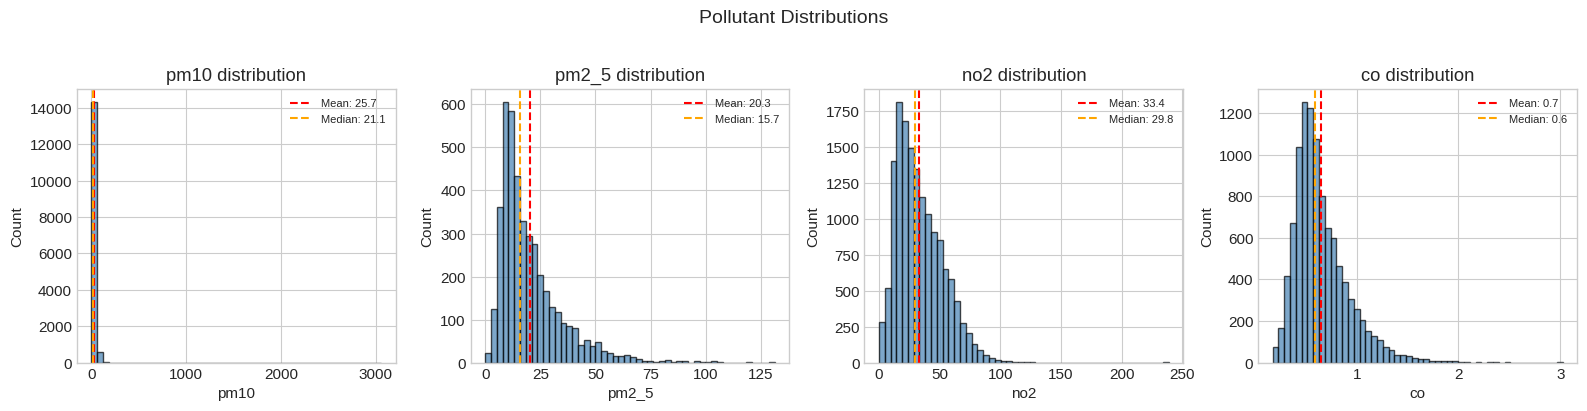

In [7]:
# Distribution histograms for pollutants
pollutants = ['pm10', 'pm2_5', 'no2', 'co']
available_pollutants = [p for p in pollutants if p in df.columns and df[p].notna().sum() > 0]

fig, axes = plt.subplots(1, len(available_pollutants), figsize=(4*len(available_pollutants), 4))
if len(available_pollutants) == 1:
    axes = [axes]

for ax, pol in zip(axes, available_pollutants):
    data = df[pol].dropna()
    ax.hist(data, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    ax.set_title(f'{pol} distribution')
    ax.set_xlabel(pol)
    ax.set_ylabel('Count')
    ax.axvline(data.mean(), color='red', linestyle='--', label=f'Mean: {data.mean():.1f}')
    ax.axvline(data.median(), color='orange', linestyle='--', label=f'Median: {data.median():.1f}')
    ax.legend(fontsize=8)

plt.suptitle('Pollutant Distributions', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('images/01_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Basic statistics
df[available_pollutants].describe()

,pm10,pm2_5,no2,co
count,14970.000000,4253.000000,14948.000000,10318.000000
mean,25.683591,20.280411,33.361956,0.653475
std,30.532179,14.686563,18.921444,0.270193
min,0.000000,0.000000,0.068250,0.175330
25%,13.170848,10.307190,18.482155,0.470683
50%,21.105250,15.733470,29.778815,0.589580
75%,32.847125,25.773420,45.645632,0.780938
max,3057.764790,131.469050,238.686710,3.021900


### 2.2 Temporal Patterns - Daily (Hour x Day of Week)

In [9]:
# Add temporal features
df['hour'] = pd.to_datetime(df['timestamp']).dt.hour
df['dayofweek'] = pd.to_datetime(df['timestamp']).dt.dayofweek
df['month'] = pd.to_datetime(df['timestamp']).dt.month
df['date'] = pd.to_datetime(df['timestamp']).dt.date

day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

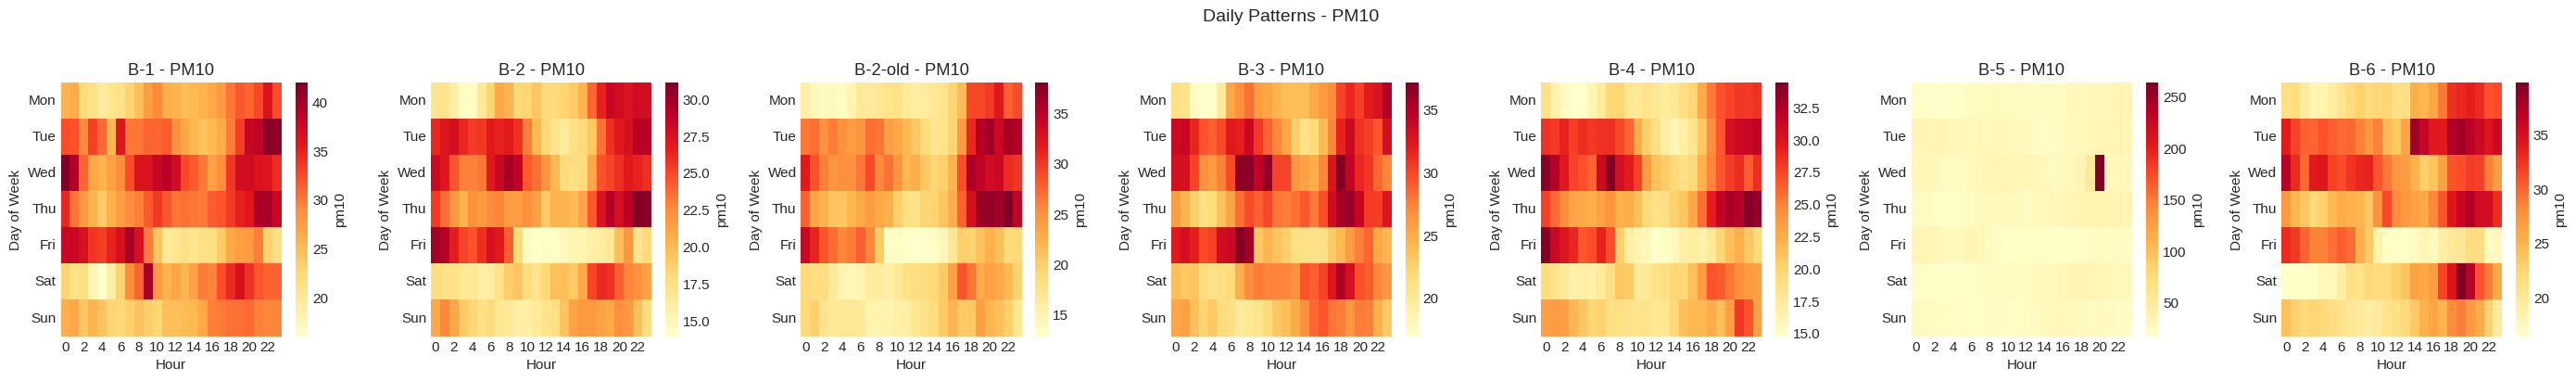

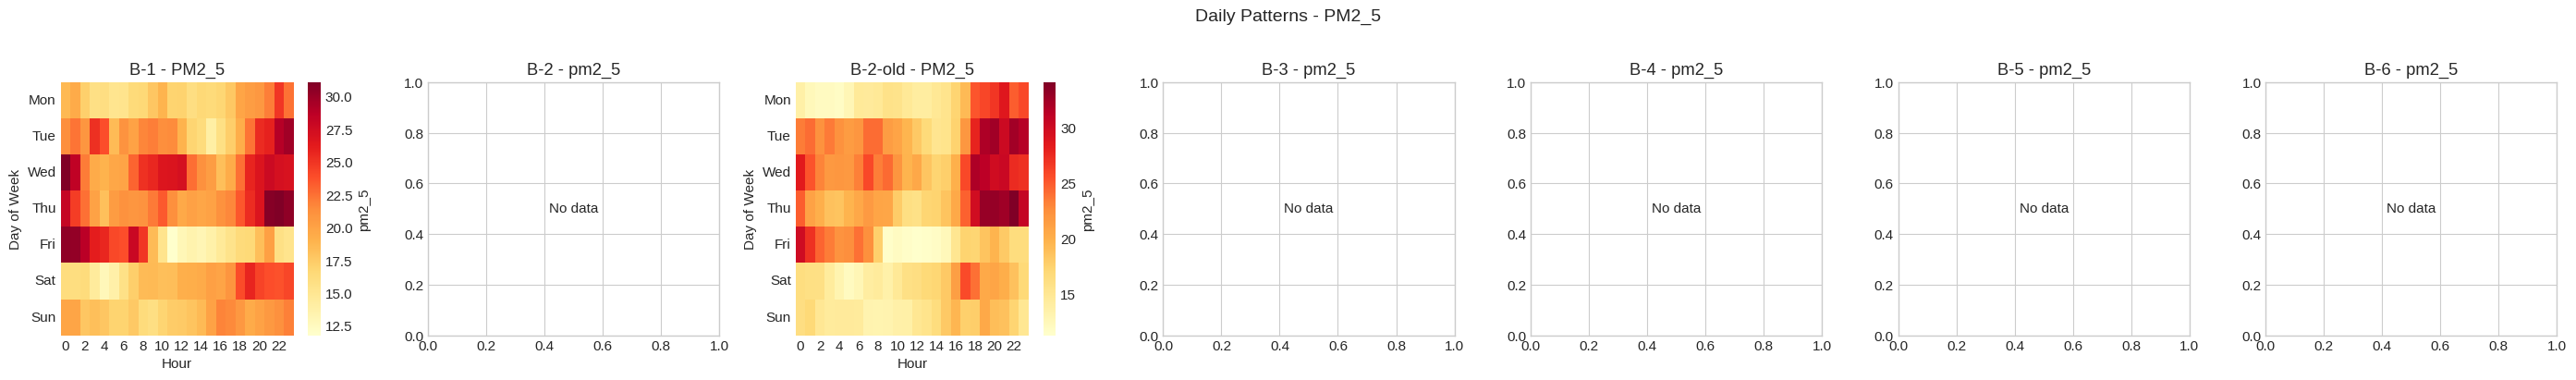

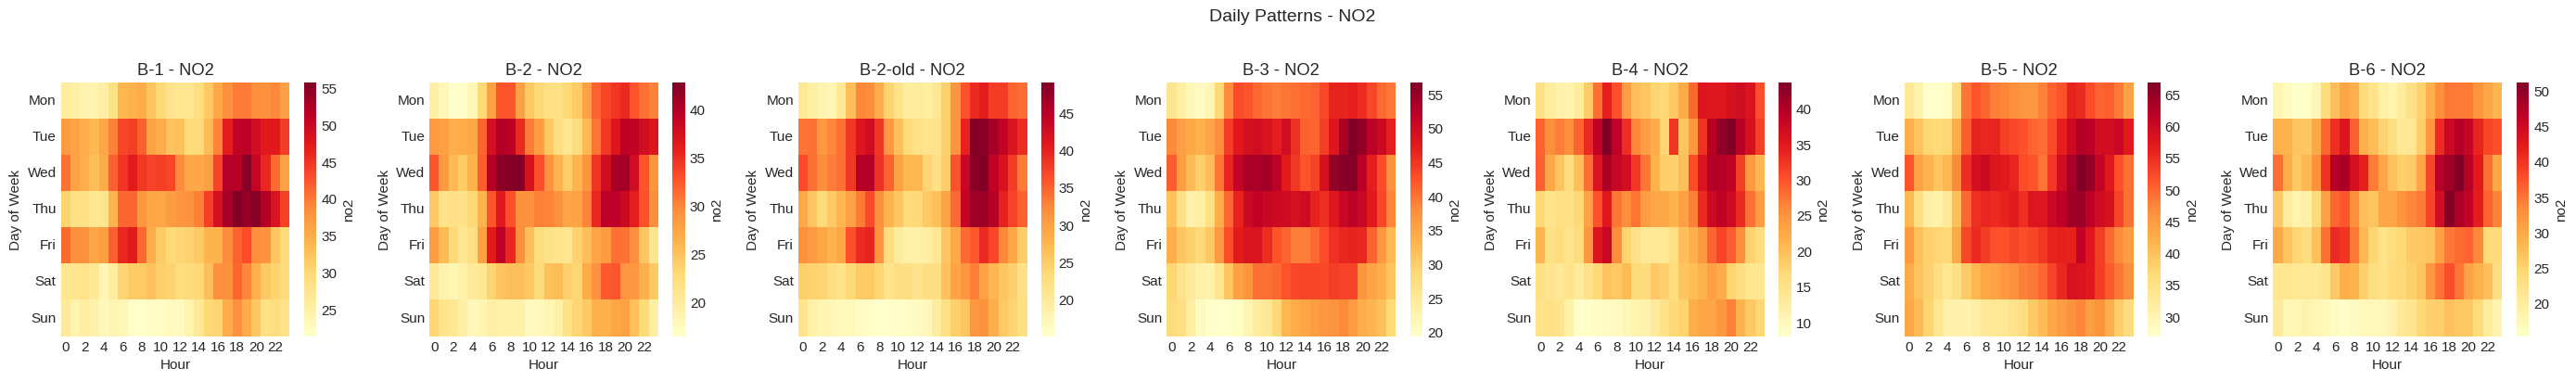

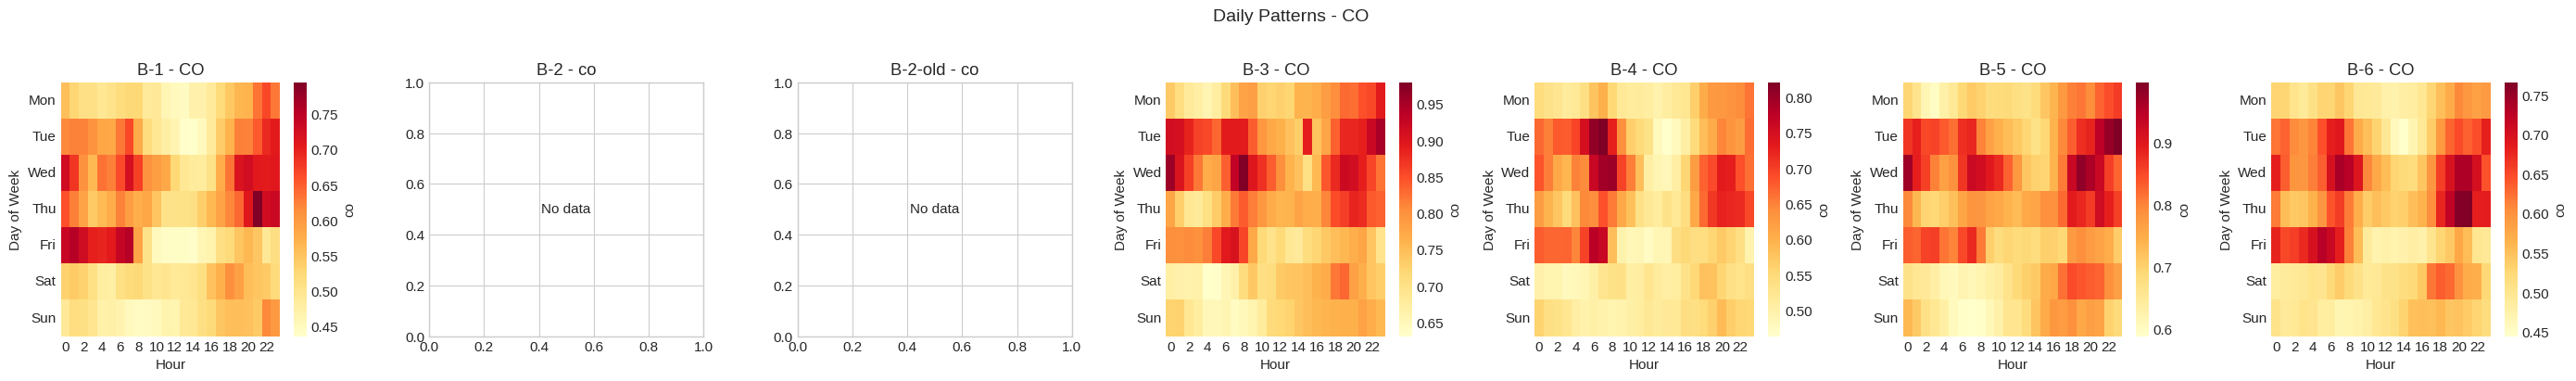

In [10]:
# Heatmaps: Hour x Day of Week for each station and pollutant
stations = df['station_id'].unique()

for pol in available_pollutants:
    n_stations = len(stations)
    fig, axes = plt.subplots(1, n_stations, figsize=(4*n_stations, 4))
    if n_stations == 1:
        axes = [axes]
    
    for ax, station in zip(axes, stations):
        station_data = df[df['station_id'] == station]
        
        if station_data[pol].notna().sum() == 0:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'{station} - {pol}')
            continue
        
        pivot = station_data.pivot_table(
            index='dayofweek', 
            columns='hour', 
            values=pol, 
            aggfunc='mean'
        )
        
        sns.heatmap(pivot, ax=ax, cmap='YlOrRd', cbar_kws={'label': pol})
        ax.set_title(f'{station} - {pol.upper()}')
        ax.set_xlabel('Hour')
        ax.set_ylabel('Day of Week')
        ax.set_yticklabels(day_names, rotation=0)
    
    plt.suptitle(f'Daily Patterns - {pol.upper()}', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(f'images/02_daily_patterns_{pol}.png', dpi=150, bbox_inches='tight')
    plt.show()

### 2.3 Seasonal Patterns - Time Series

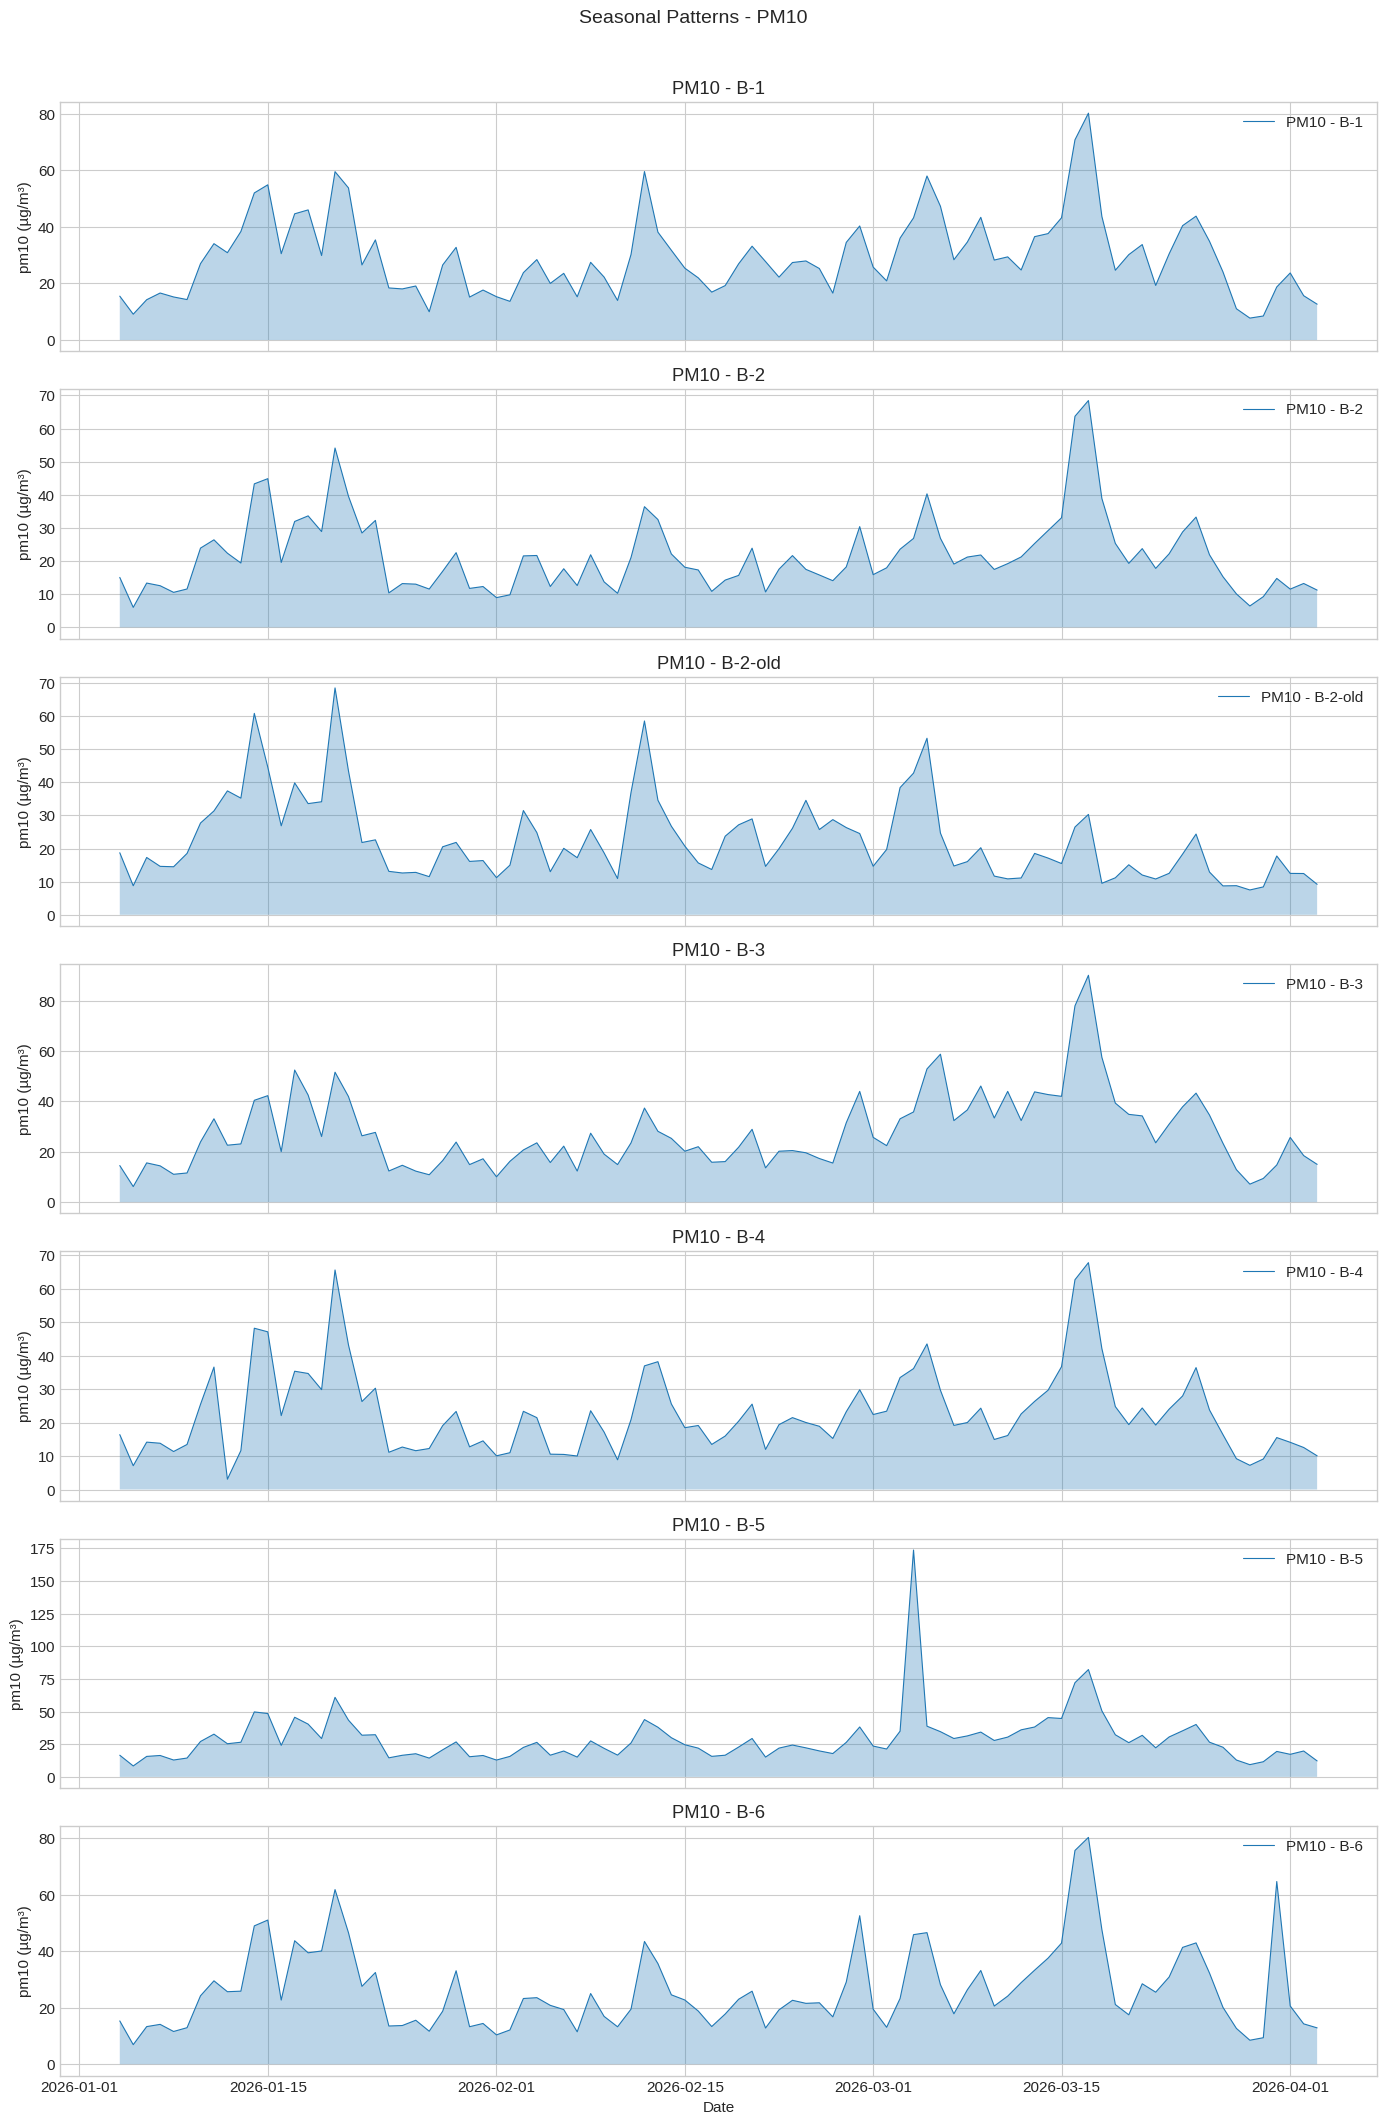

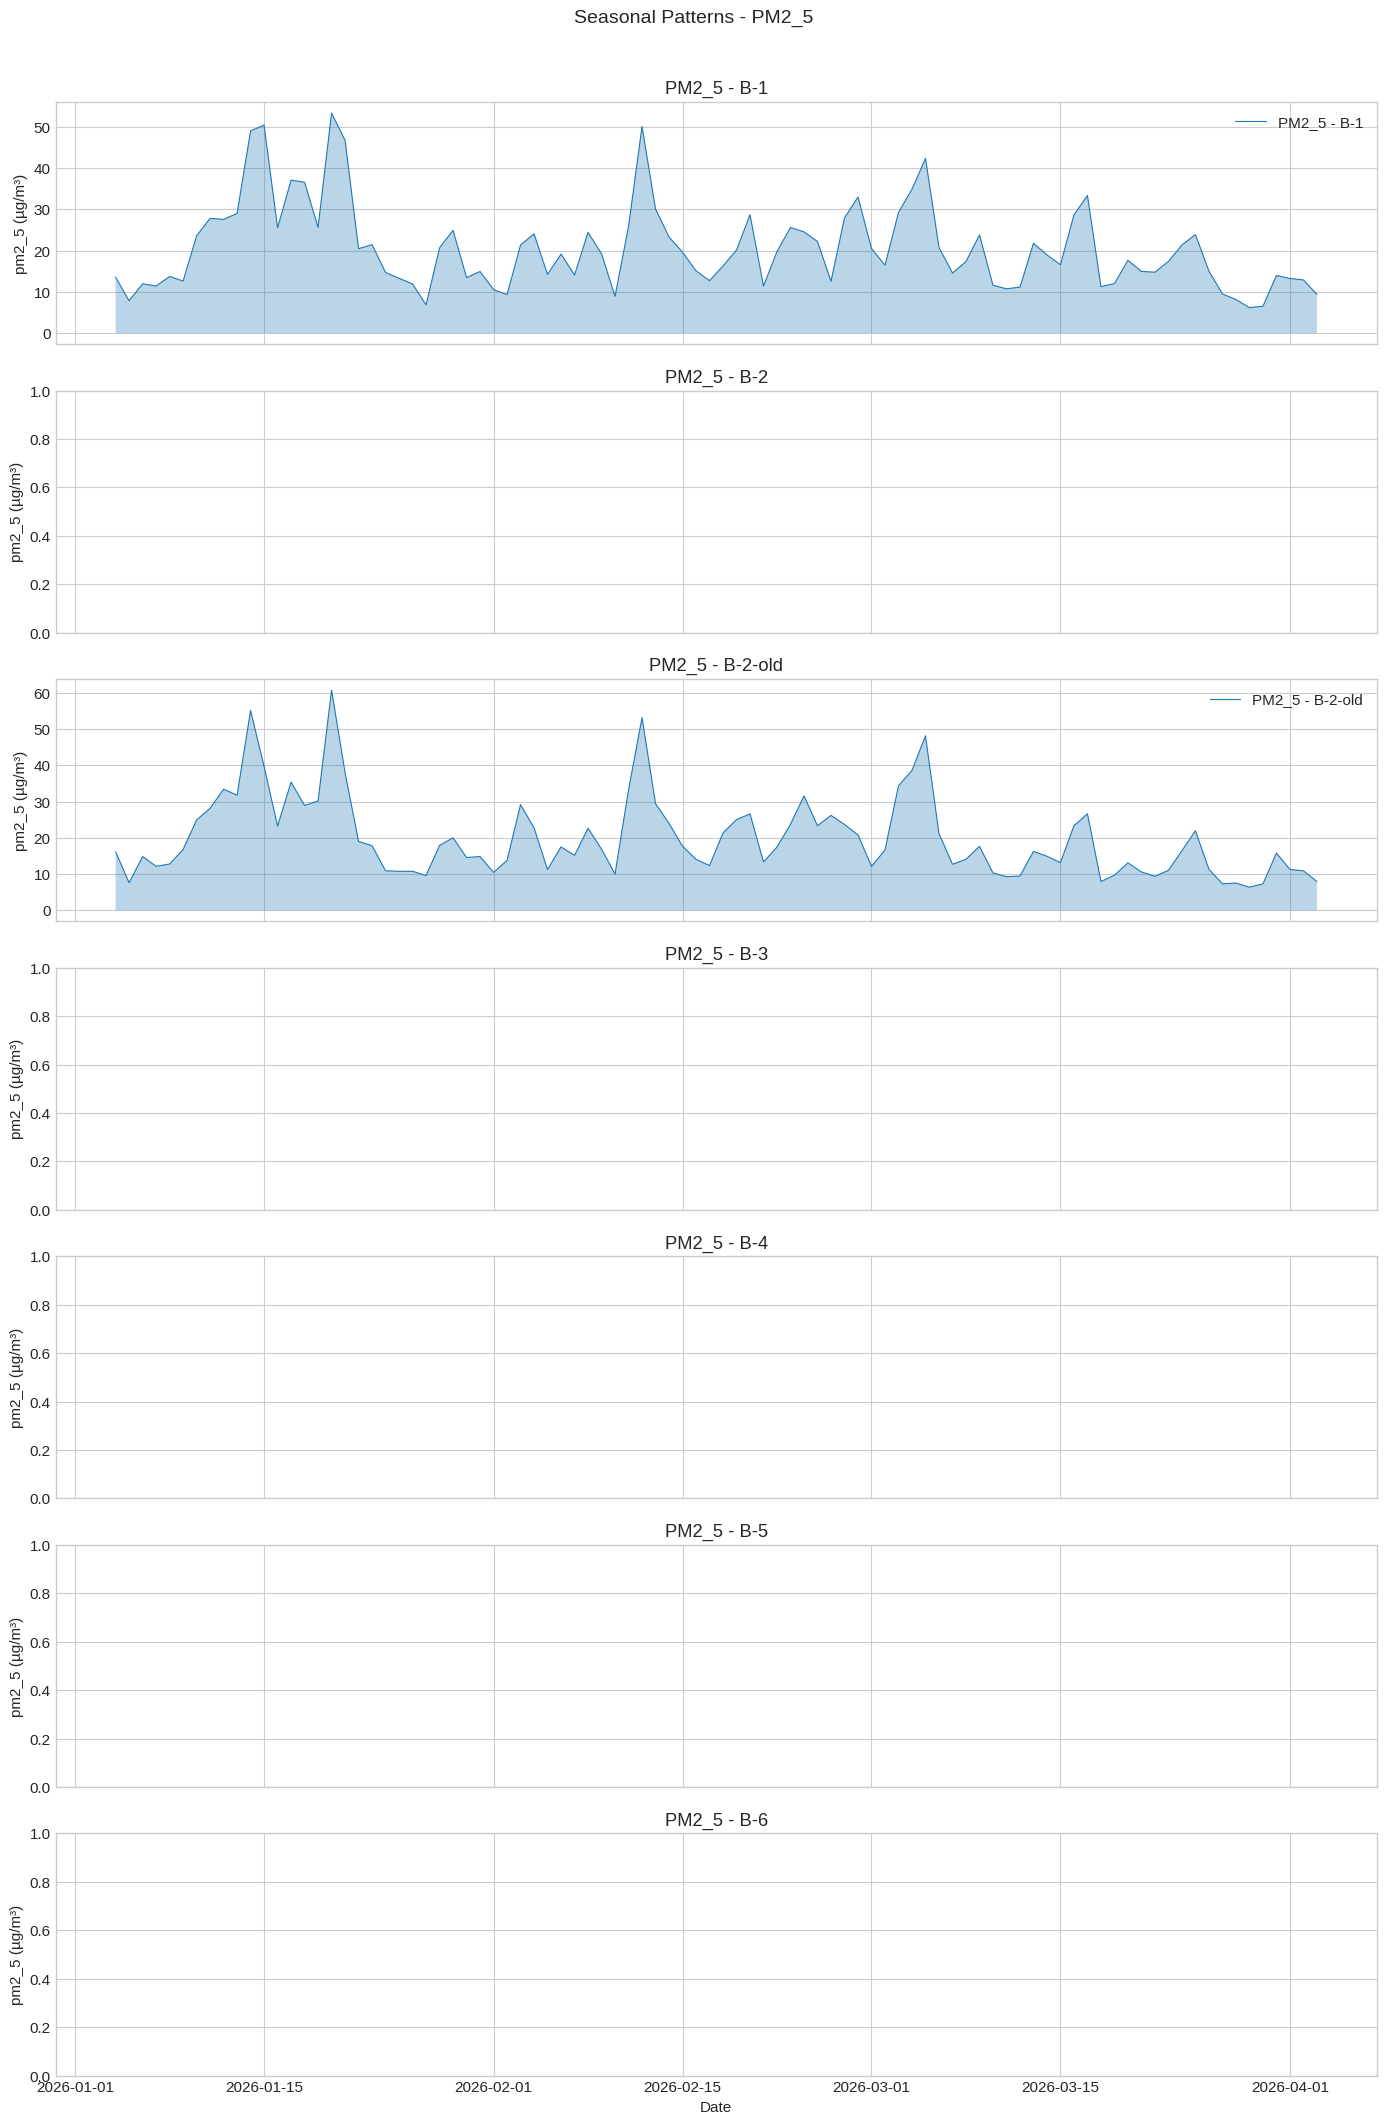

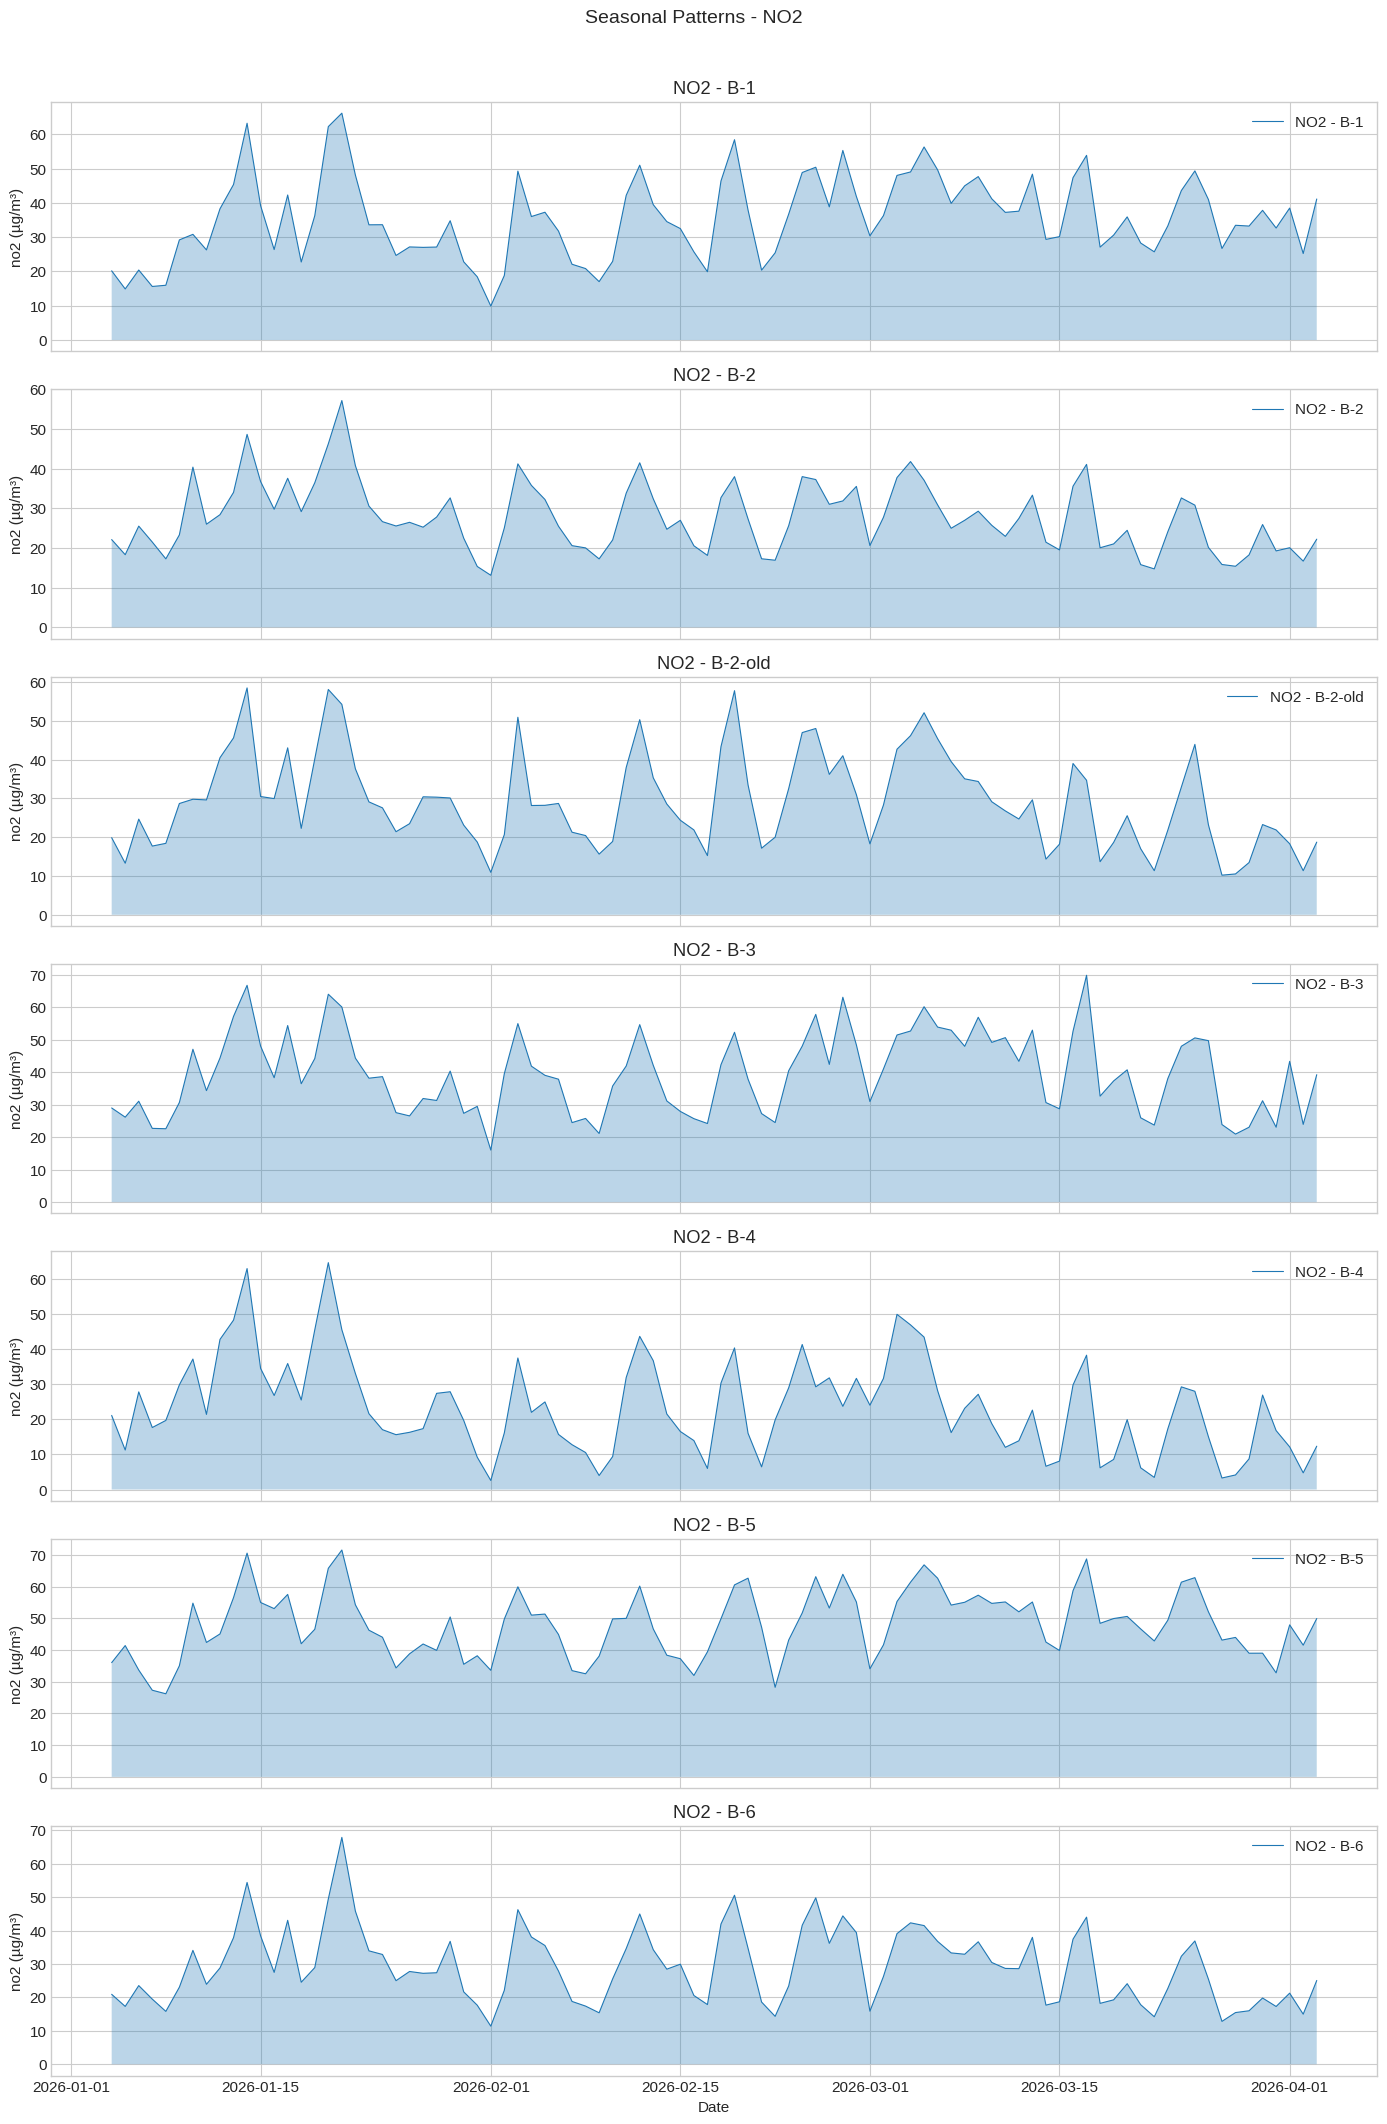

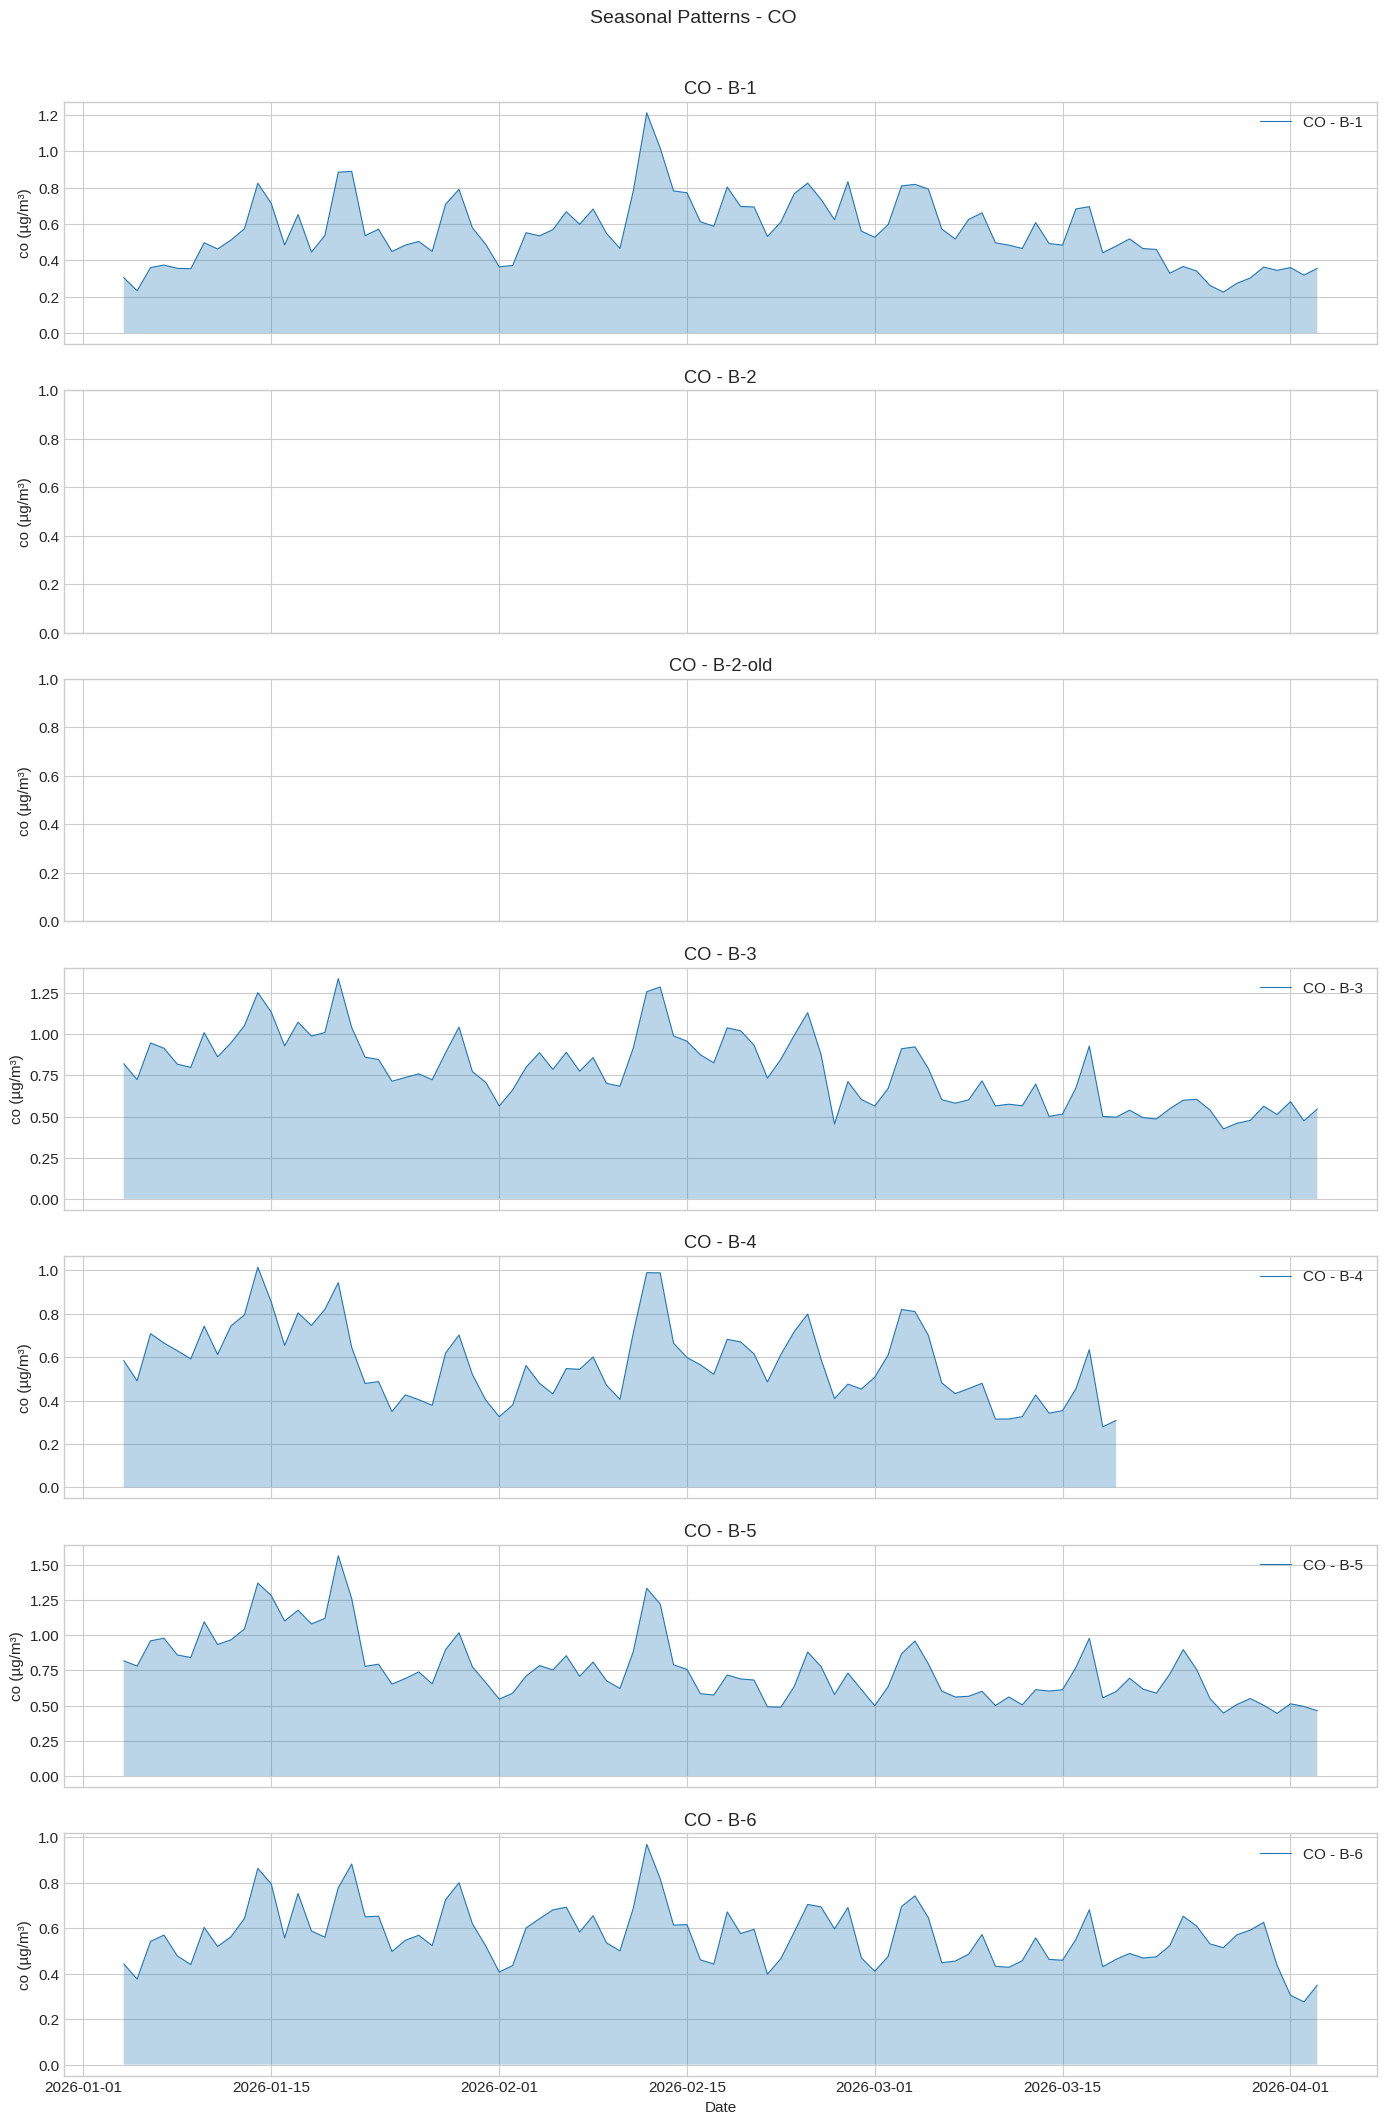

In [ ]:
# Time series plot for each pollutant per station
for pol in available_pollutants:
    fig, axes = plt.subplots(len(stations), 1, figsize=(14, 3*len(stations)), sharex=True)
    if len(stations) == 1:
        axes = [axes]
    
    for ax, station in zip(axes, stations):
        station_data = df[df['station_id'] == station].sort_values('timestamp')
        
        if station_data[pol].notna().sum() > 0:
            # Daily average for smoother plot
            daily = station_data.groupby('date')[pol].mean()
            ax.plot(daily.index, daily.values, label=f'{pol.upper()} - {station}', linewidth=0.8)
            ax.fill_between(daily.index, daily.values, alpha=0.3)
        
        ax.set_ylabel(f'{pol} (µg/m³)')
        ax.set_title(f'{pol.upper()} - {station}')
        ax.legend(loc='upper right')
    
    axes[-1].set_xlabel('Date')
    plt.suptitle(f'Seasonal Patterns - {pol.upper()}', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig(f'images/03_seasonal_{pol}.png', dpi=150, bbox_inches='tight')
    plt.show()

### 2.4 Correlation Heatmap

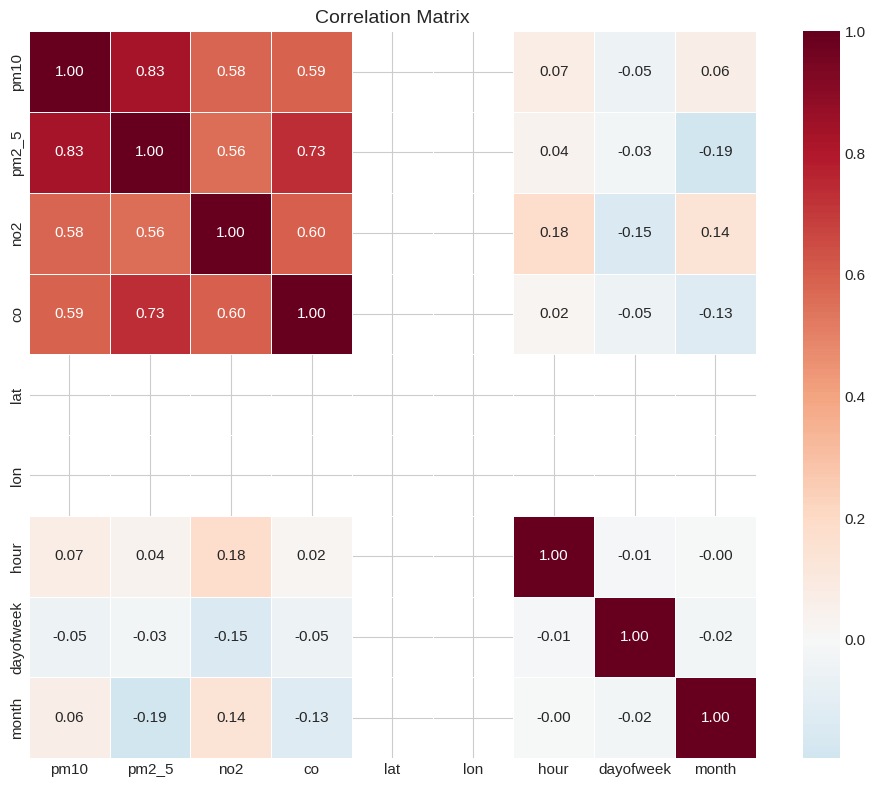

In [12]:
# Correlation between pollutants and features
corr_cols = available_pollutants + ['lat', 'lon', 'hour', 'dayofweek', 'month']
corr_data = df[corr_cols].dropna()

if len(corr_data) > 100:
    corr_matrix = corr_data.corr()
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, 
                fmt='.2f', square=True, linewidths=0.5)
    plt.title('Correlation Matrix', fontsize=14)
    plt.tight_layout()
    plt.savefig('images/04_correlation_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Not enough data for correlation analysis")

### 2.5 Station Locations Map

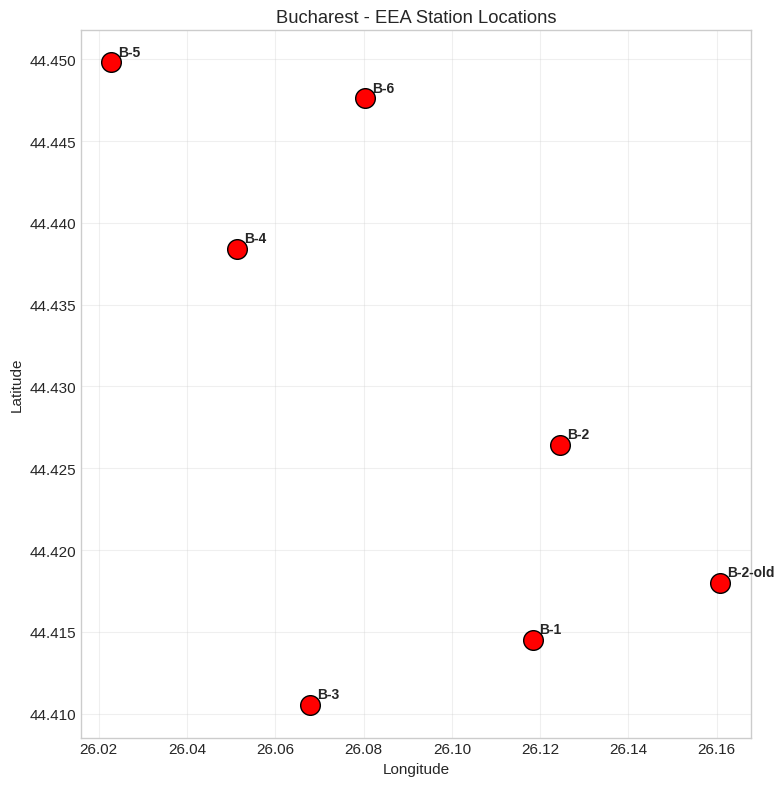

In [13]:
# Simple scatter plot of station locations
station_locs = df.groupby('station_id').agg({'lat': 'first', 'lon': 'first'}).reset_index()

plt.figure(figsize=(8, 8))
plt.scatter(station_locs['lon'], station_locs['lat'], s=200, c='red', edgecolors='black', zorder=5)

for _, row in station_locs.iterrows():
    plt.annotate(row['station_id'], (row['lon'], row['lat']), 
                 xytext=(5, 5), textcoords='offset points', fontsize=10, fontweight='bold')

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Bucharest - EEA Station Locations')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/05_station_locations.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Model Training

Using PolPred: IDW (Inverse Distance Weighting) + HistGradientBoostingRegressor

In [14]:
# Import polpred
import sys
sys.path.insert(0, '.')  # Add current directory

from polpred import PolPredModel
from polpred.config import PolPredConfig

print("PolPred imported successfully!")

PolPred imported successfully!


In [15]:
# Prepare data for training
train_df = df[['timestamp', 'station_id', 'lat', 'lon', 'pm10', 'pm2_5', 'no2', 'co']].copy()

# Check data quality
print("Training data shape:", train_df.shape)
print("\nNull values:")
print(train_df.isnull().sum())
print("\nUnique stations:", train_df['station_id'].nunique())
print("Unique timestamps:", train_df['timestamp'].nunique())

Training data shape: (15017, 8)

Null values:
timestamp         0
station_id        0
lat               0
lon               0
pm10             47
pm2_5         10764
no2              69
co             4699
dtype: int64

Unique stations: 7
Unique timestamps: 2151


In [16]:
# Configure model
config = PolPredConfig(
    timestamp_col="timestamp",
    station_id_col="station_id",
    latitude_col="lat",
    longitude_col="lon",
    pollutant_columns=("pm10", "pm2_5", "no2", "co"),
    nearest_station_count=3,
    distance_exponents=(0.5, 1.0, 1.5),
)

model = PolPredModel(config=config)
print("Model configured!")
print(f"Pollutants: {config.pollutant_columns}")
print(f"IDW exponents: {config.distance_exponents}")
print(f"Nearest stations: {config.nearest_station_count}")

Model configured!
Pollutants: ('pm10', 'pm2_5', 'no2', 'co')
IDW exponents: (0.5, 1.0, 1.5)
Nearest stations: 3


## 4. Model Evaluation (Holdout)

Split data chronologically: train on earlier data, test on latest N timestamps.

In [17]:
# Evaluate with holdout
HOLDOUT_STEPS = 100  # Last 100 timestamps (~4 days of hourly data)

print(f"Evaluating with holdout_steps={HOLDOUT_STEPS}...")
print("This may take a few minutes...\n")

try:
    metrics, predictions = model.evaluate_holdout(train_df, holdout_steps=HOLDOUT_STEPS)
    print("Evaluation complete!")
except Exception as e:
    print(f"Error during evaluation: {e}")
    metrics = None
    predictions = None

Evaluating with holdout_steps=100...
This may take a few minutes...

Evaluation complete!


In [18]:
# Display metrics
if metrics is not None:
    print("="*60)
    print("HOLDOUT EVALUATION METRICS")
    print("="*60)
    
    # Overall metrics (aggregated across all stations)
    overall = metrics[metrics['station_id'] == '__all__'].copy()
    print("\nOverall Performance:")
    print(overall[['pollutant', 'count', 'mae', 'rmse', 'r2']].to_string(index=False))
    
    # Per-station metrics
    print("\nPer-Station Performance:")
    per_station = metrics[metrics['station_id'] != '__all__'].copy()
    print(per_station[['station_id', 'pollutant', 'count', 'mae', 'rmse', 'r2']].to_string(index=False))

HOLDOUT EVALUATION METRICS

Overall Performance:
pollutant  count      mae      rmse        r2
       co    395 0.099245  0.139377 -0.110447
      no2    691 4.674535  6.228995  0.831082
     pm10    694 4.897812 15.571096  0.165214
    pm2_5    200 2.735316  4.785481  0.470613

Per-Station Performance:
station_id pollutant  count       mae      rmse        r2
       B-1        co    100  0.034291  0.045015  0.679488
       B-3        co    100  0.054878  0.067902  0.514977
       B-5        co     95  0.073935  0.085719  0.327508
       B-6        co    100  0.232610  0.251227 -2.581932
       B-1       no2    100  5.420919  6.913377  0.331037
       B-2       no2    100  3.329348  4.348349  0.635857
   B-2-old       no2    100  3.674745  5.450011  0.743750
       B-3       no2    100  6.419987  8.112518  0.724391
       B-4       no2     96  5.120821  6.257830  0.646031
       B-5       no2     95  5.183279  6.093776  0.802079
       B-6       no2    100  3.615932  5.746363  0.741029

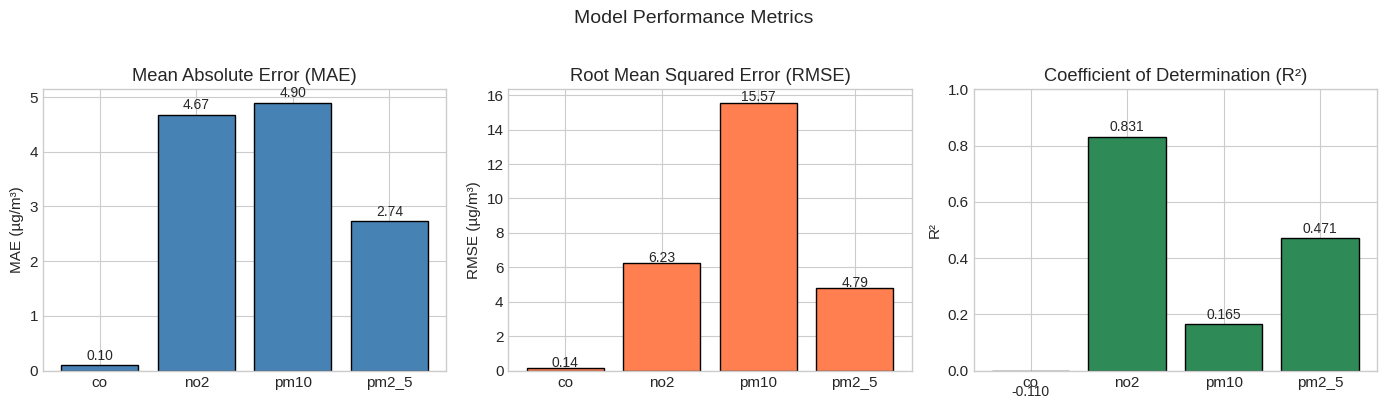

In [19]:
# Metrics bar chart
if metrics is not None:
    overall = metrics[metrics['station_id'] == '__all__'].copy()
    
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    
    # MAE
    axes[0].bar(overall['pollutant'], overall['mae'], color='steelblue', edgecolor='black')
    axes[0].set_title('Mean Absolute Error (MAE)')
    axes[0].set_ylabel('MAE (µg/m³)')
    for i, v in enumerate(overall['mae']):
        axes[0].text(i, v + 0.1, f'{v:.2f}', ha='center', fontsize=10)
    
    # RMSE
    axes[1].bar(overall['pollutant'], overall['rmse'], color='coral', edgecolor='black')
    axes[1].set_title('Root Mean Squared Error (RMSE)')
    axes[1].set_ylabel('RMSE (µg/m³)')
    for i, v in enumerate(overall['rmse']):
        axes[1].text(i, v + 0.1, f'{v:.2f}', ha='center', fontsize=10)
    
    # R²
    axes[2].bar(overall['pollutant'], overall['r2'], color='seagreen', edgecolor='black')
    axes[2].set_title('Coefficient of Determination (R²)')
    axes[2].set_ylabel('R²')
    axes[2].set_ylim(0, 1)
    for i, v in enumerate(overall['r2']):
        axes[2].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=10)
    
    plt.suptitle('Model Performance Metrics', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig('images/06_metrics.png', dpi=150, bbox_inches='tight')
    plt.show()

### 4.1 Real vs Predicted Time Series

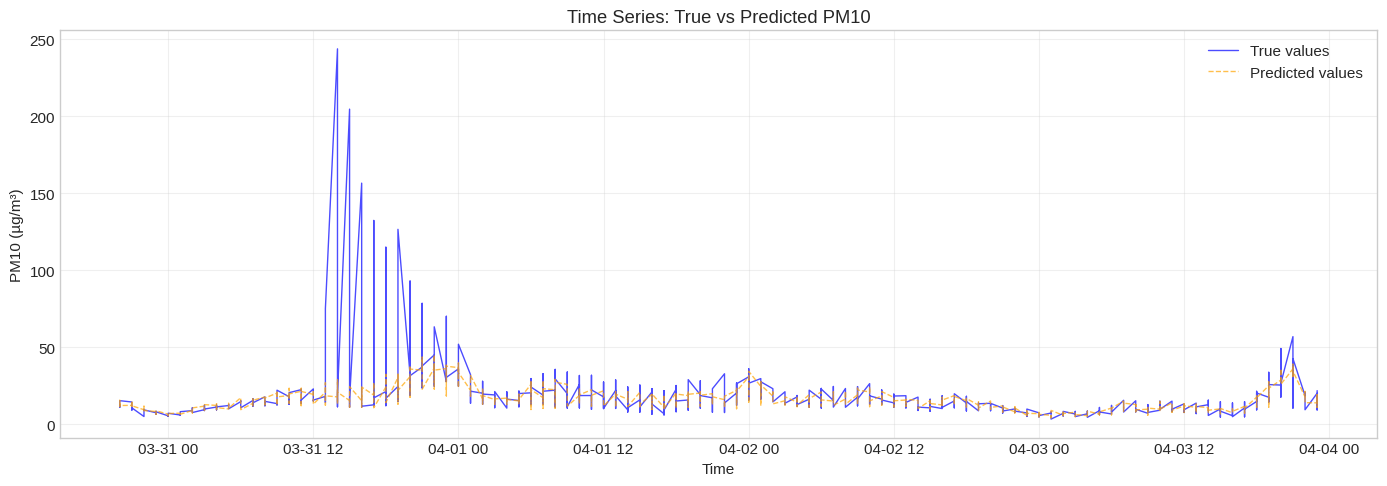

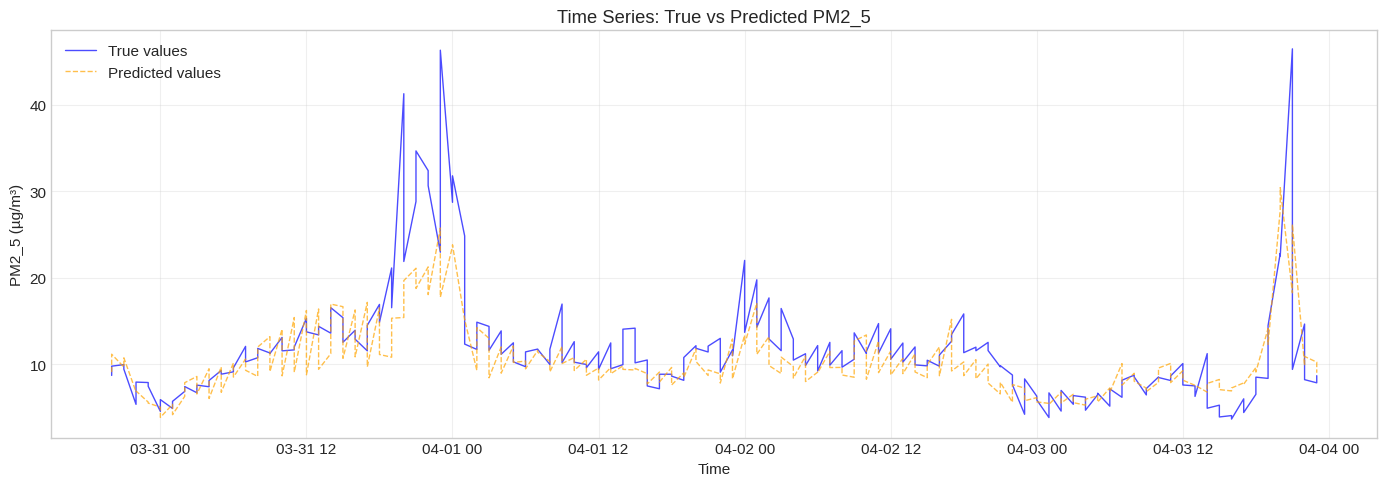

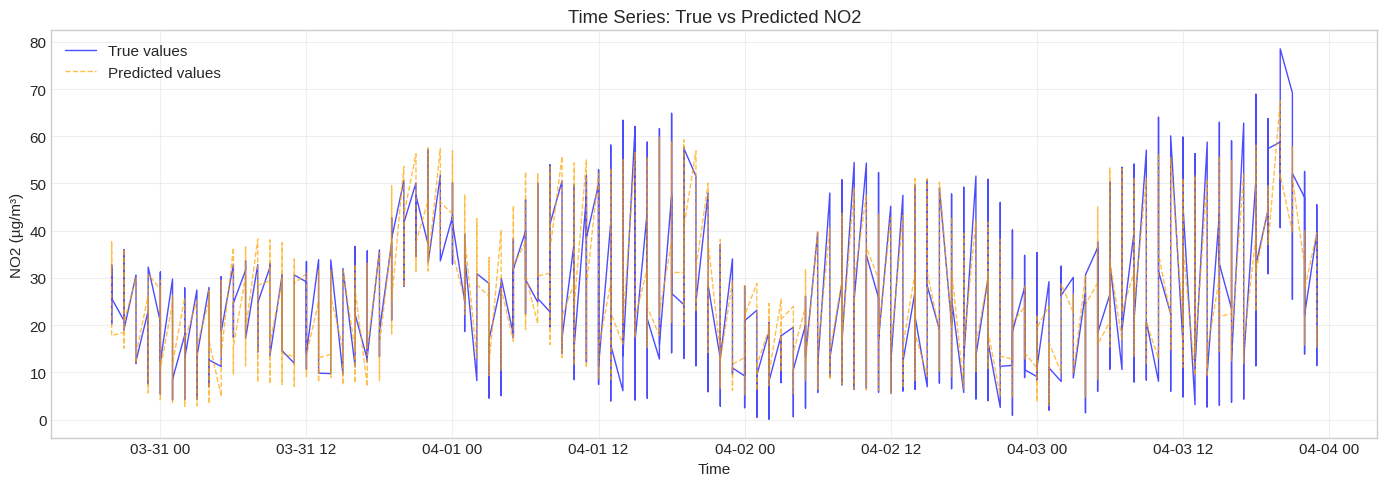

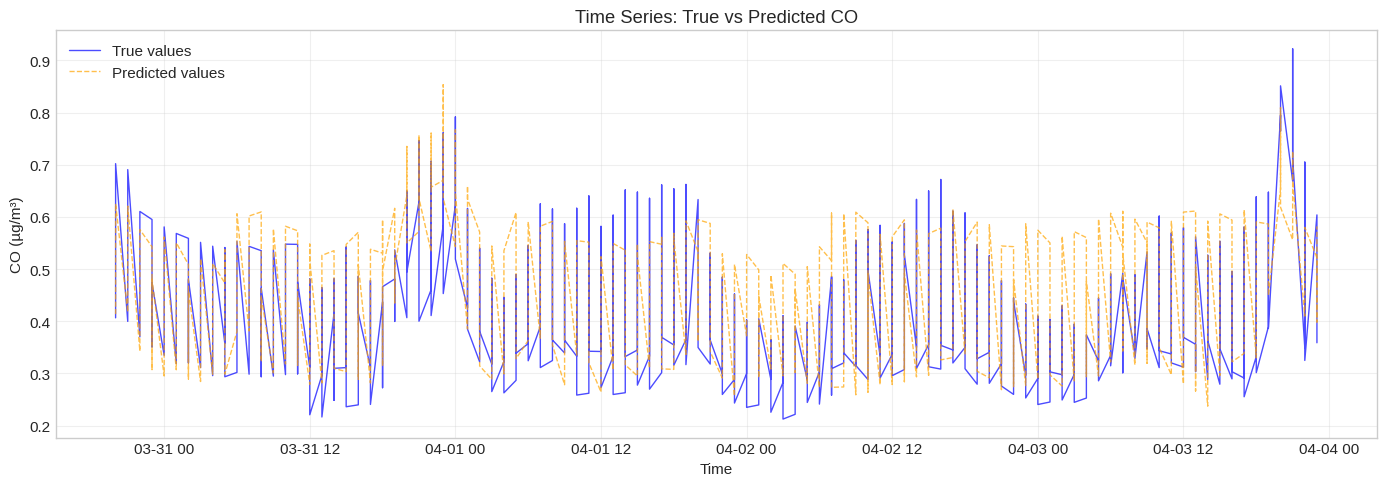

In [20]:
# Plot real vs predicted for each pollutant
if predictions is not None:
    pollutants_in_predictions = predictions['pollutant'].unique()
    
    for pol in pollutants_in_predictions:
        pol_data = predictions[predictions['pollutant'] == pol].copy()
        pol_data = pol_data.sort_values('timestamp')
        
        plt.figure(figsize=(14, 5))
        plt.plot(pol_data['timestamp'], pol_data['actual'], 
                 label='True values', color='blue', alpha=0.7, linewidth=1)
        plt.plot(pol_data['timestamp'], pol_data['pred'], 
                 label='Predicted values', color='orange', alpha=0.7, linewidth=1, linestyle='--')
        
        plt.xlabel('Time')
        plt.ylabel(f'{pol.upper()} (µg/m³)')
        plt.title(f'Time Series: True vs Predicted {pol.upper()}')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(f'images/07_real_vs_predicted_{pol}.png', dpi=150, bbox_inches='tight')
        plt.show()

### 4.2 Scatter Plot: Actual vs Predicted

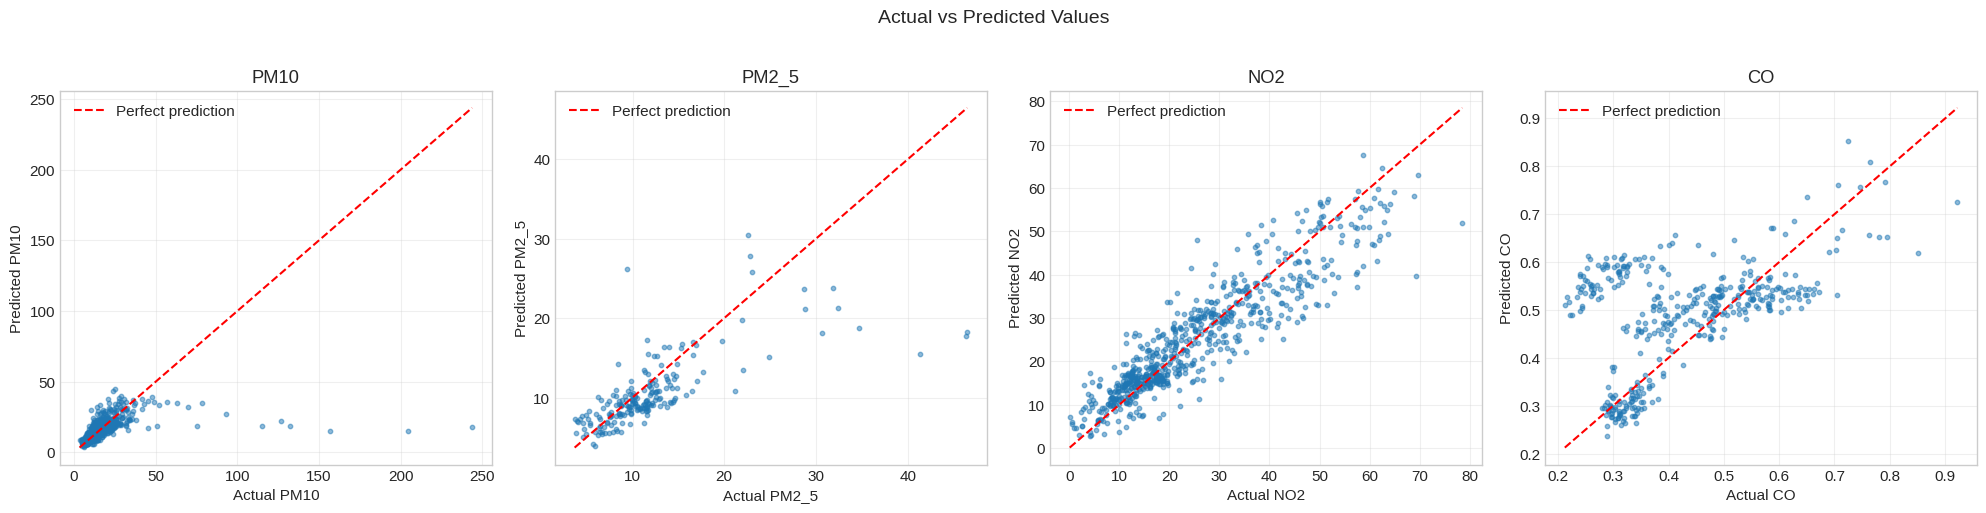

In [21]:
# Scatter plot actual vs predicted
if predictions is not None:
    pollutants_in_predictions = predictions['pollutant'].unique()
    n_pols = len(pollutants_in_predictions)
    
    fig, axes = plt.subplots(1, n_pols, figsize=(5*n_pols, 5))
    if n_pols == 1:
        axes = [axes]
    
    for ax, pol in zip(axes, pollutants_in_predictions):
        pol_data = predictions[predictions['pollutant'] == pol]
        
        ax.scatter(pol_data['actual'], pol_data['pred'], alpha=0.5, s=10)
        
        # Perfect prediction line
        min_val = min(pol_data['actual'].min(), pol_data['pred'].min())
        max_val = max(pol_data['actual'].max(), pol_data['pred'].max())
        ax.plot([min_val, max_val], [min_val, max_val], 'r--', label='Perfect prediction')
        
        ax.set_xlabel(f'Actual {pol.upper()}')
        ax.set_ylabel(f'Predicted {pol.upper()}')
        ax.set_title(f'{pol.upper()}')
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    plt.suptitle('Actual vs Predicted Values', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig('images/08_scatter_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
    plt.show()

### 4.3 Residuals Distribution

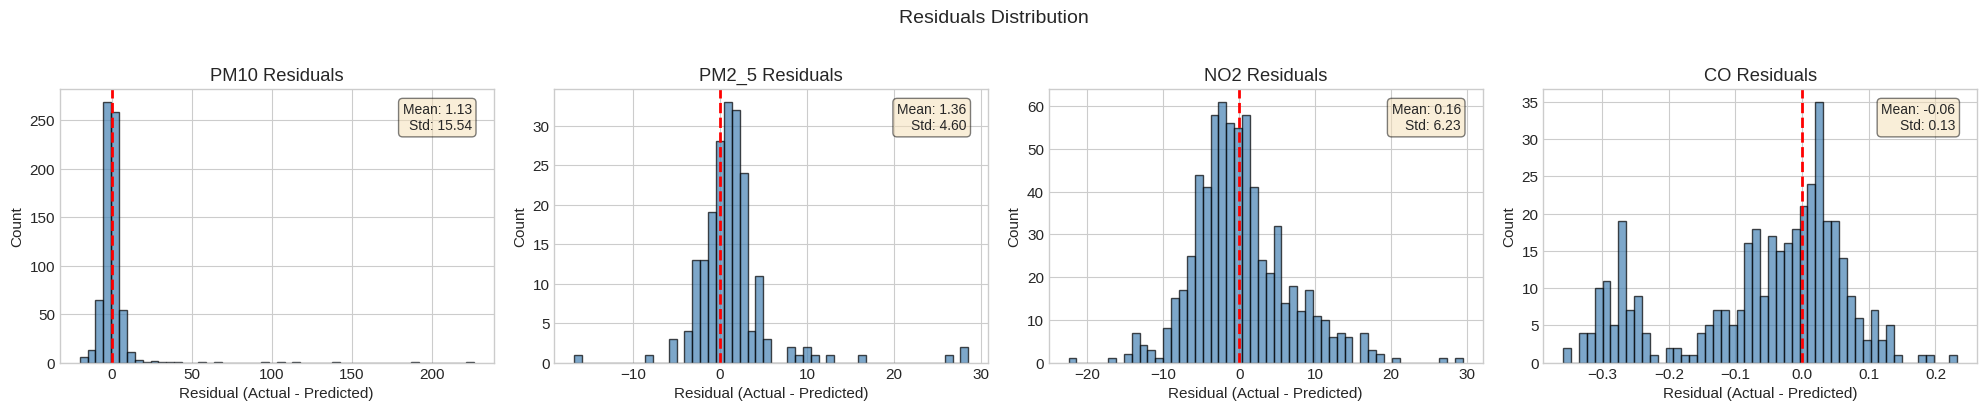

In [22]:
# Residuals histogram
if predictions is not None:
    predictions['residual'] = predictions['actual'] - predictions['pred']
    
    pollutants_in_predictions = predictions['pollutant'].unique()
    n_pols = len(pollutants_in_predictions)
    
    fig, axes = plt.subplots(1, n_pols, figsize=(5*n_pols, 4))
    if n_pols == 1:
        axes = [axes]
    
    for ax, pol in zip(axes, pollutants_in_predictions):
        pol_data = predictions[predictions['pollutant'] == pol]
        
        ax.hist(pol_data['residual'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
        ax.axvline(0, color='red', linestyle='--', linewidth=2)
        ax.set_xlabel('Residual (Actual - Predicted)')
        ax.set_ylabel('Count')
        ax.set_title(f'{pol.upper()} Residuals')
        
        # Add stats
        mean_res = pol_data['residual'].mean()
        std_res = pol_data['residual'].std()
        ax.text(0.95, 0.95, f'Mean: {mean_res:.2f}\nStd: {std_res:.2f}', 
                transform=ax.transAxes, ha='right', va='top', fontsize=10,
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.suptitle('Residuals Distribution', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig('images/09_residuals.png', dpi=150, bbox_inches='tight')
    plt.show()

## 5. Train Final Model and Save

In [23]:
# Train on full dataset
print("Training final model on full dataset...")

final_model = PolPredModel(config=config)
final_model.fit(train_df)

print(f"\nModel trained successfully!")
print(f"Feature columns: {len(final_model.feature_columns_)}")
print(f"Pollutant models: {list(final_model.models_.keys())}")

Training final model on full dataset...

Model trained successfully!
Feature columns: 95
Pollutant models: ['pm10', 'pm2_5', 'no2', 'co']


In [24]:
# Save model
MODEL_OUTPUT_PATH = "./model/polpred.pkl"

import os
os.makedirs(os.path.dirname(MODEL_OUTPUT_PATH), exist_ok=True)

final_model.save(MODEL_OUTPUT_PATH)
print(f"Model saved to {MODEL_OUTPUT_PATH}")
print(f"Size: {os.path.getsize(MODEL_OUTPUT_PATH) / 1024:.1f} KB")

Model saved to ./model/polpred.pkl
Size: 10996.9 KB


## 6. Test Prediction

In [25]:
# Test prediction at a random point
from polpred import PolPredModel

# Load saved model
loaded_model = PolPredModel.load(MODEL_OUTPUT_PATH)

# Get latest station state
latest_timestamp = train_df['timestamp'].max()
latest_state = train_df[train_df['timestamp'] == latest_timestamp].to_dict('records')

# Predict at a point in central Bucharest
test_lat, test_lon = 44.4268, 26.1025  # Near Universitate

prediction = loaded_model.predict_at(
    latitude=test_lat,
    longitude=test_lon,
    station_state=latest_state,
    timestamp=str(latest_timestamp)
)

print(f"Prediction at ({test_lat}, {test_lon}):")
for pollutant, value in prediction.items():
    print(f"  {pollutant}: {value:.2f} µg/m³")

Prediction at (44.4268, 26.1025):
  pm10: 14.86 µg/m³
  pm2_5: 10.96 µg/m³
  no2: 10.37 µg/m³
  co: 0.32 µg/m³


## 7. Summary

### Model Performance

In [26]:
if metrics is not None:
    overall = metrics[metrics['station_id'] == '__all__'].copy()
    
    print("="*60)
    print("FINAL MODEL PERFORMANCE SUMMARY")
    print("="*60)
    print(f"\nData: {len(train_df)} samples from {train_df['station_id'].nunique()} stations")
    print(f"Date range: {train_df['timestamp'].min()} to {train_df['timestamp'].max()}")
    print(f"\nModel: IDW + HistGradientBoostingRegressor")
    print(f"Features: Spatial (IDW with exp 0.5, 1.0, 1.5) + Temporal (day, month sin/cos)")
    print(f"\nPerformance Metrics:")
    print("-"*60)
    
    for _, row in overall.iterrows():
        print(f"\n{row['pollutant'].upper()}:")
        print(f"  MAE:  {row['mae']:.2f} µg/m³")
        print(f"  RMSE: {row['rmse']:.2f} µg/m³")
        print(f"  R²:   {row['r2']:.3f}")

FINAL MODEL PERFORMANCE SUMMARY

Data: 15017 samples from 7 stations
Date range: 2026-01-04 00:00:00 to 2026-04-03 23:00:00

Model: IDW + HistGradientBoostingRegressor
Features: Spatial (IDW with exp 0.5, 1.0, 1.5) + Temporal (day, month sin/cos)

Performance Metrics:
------------------------------------------------------------

CO:
  MAE:  0.10 µg/m³
  RMSE: 0.14 µg/m³
  R²:   -0.110

NO2:
  MAE:  4.67 µg/m³
  RMSE: 6.23 µg/m³
  R²:   0.831

PM10:
  MAE:  4.90 µg/m³
  RMSE: 15.57 µg/m³
  R²:   0.165

PM2_5:
  MAE:  2.74 µg/m³
  RMSE: 4.79 µg/m³
  R²:   0.471


In [28]:
# List generated figures
import glob

print("\nGenerated figures:")
for f in sorted(glob.glob("images/*.png")):
    print(f"  - {f}")


Generated figures:
  - images/01_distributions.png
  - images/02_daily_patterns_co.png
  - images/02_daily_patterns_no2.png
  - images/02_daily_patterns_pm10.png
  - images/02_daily_patterns_pm2_5.png
  - images/03_seasonal_co.png
  - images/03_seasonal_no2.png
  - images/03_seasonal_pm10.png
  - images/03_seasonal_pm2_5.png
  - images/04_correlation_matrix.png
  - images/05_station_locations.png
  - images/06_metrics.png
  - images/07_real_vs_predicted_co.png
  - images/07_real_vs_predicted_no2.png
  - images/07_real_vs_predicted_pm10.png
  - images/07_real_vs_predicted_pm2_5.png
  - images/08_scatter_actual_vs_predicted.png
  - images/09_residuals.png
